# 03 · Прокси-метрика против целевой (расчёты для статьи)

Ноутбук обязан проходить сверху вниз на перезапущенном ядре.

**Вопрос статьи.** Активация оффера — метрика дешёвая и массовая, покупка с
партнёрским кэшбэком — то, ради чего кампания существует. Совпадают ли клиенты,
которых отбирает модель, обученная на активации, с теми, кого отбирает модель,
обученная на покупке? И если нет — сколько ценности теряется.

**Что сравнивается.** Три величины на отложенной выборке:

| величина | что показывает |
|---|---|
| tau истинных CATE | потолок согласия: сколько его есть в самой задаче |
| tau оценок моделей | сколько согласия доходит до практики после обучения |
| доля ценности от оракула | что теряется при отборе по прокси-метрике |

Разрыв между первой и второй — вклад шума обучения; сам потолок ниже единицы —
свойство задачи, разобранное в ноутбуке 02.

**Что ограничивает выводы со стороны данных.** Ковариаты и базовые уровни
отклика взяты из выгрузки кэшбэка, у которой окна наблюдения разной длины
(7 месяцев против 3), а точных границ окна «последние 3 месяца» в документации
нет и получить их не удалось. Поэтому здесь нет ни одного утверждения с
привязкой к календарю, сезонности или к абсолютным рублям: всё, что считается
ниже, — это доли отклика и порядок клиентов. Подробности — ноутбук 01,
`DATA_PASSPORT.md`, решения №30 и №31.

**Все метрики считаются только на отложенной выборке.** На обучающей Qini
показывает способность к переобучению, а не качество ранжирования: у
преобразования класса Qini на обучении 0.47 против 0.03 на отложенной.


In [12]:
# параметры и константы
from pathlib import Path
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))

from uplift_system.config import load_config  # noqa: E402
from uplift_system.datasets.synthetic import generate, load_covariates  # noqa: E402
from uplift_system.evaluation import ground_truth as G  # noqa: E402
from uplift_system.evaluation import metrics as M  # noqa: E402
from uplift_system.experiment.simulate import (  # noqa: E402
    randomize, realize_outcome, split_train_holdout,
)
from uplift_system.models.meta import build  # noqa: E402
from uplift_system.paths import PROJECT_PREFIX, out_path  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110})

SIM = load_config(PROJECT_DIR / "configs" / "sim_base.yaml", required=("target", "effect"))
EXP = load_config(PROJECT_DIR / "configs" / "experiment.yaml", required=("design", "grid"))
MODELS = load_config(PROJECT_DIR / "configs" / "models.yaml", required=("base_learner",))

SEED = int(SIM["seed"])
RUN_DATE = pd.Timestamp.today().date().isoformat()
HOLDOUT = float(EXP["validation"]["holdout_share"])
TOP_K = 0.3                     # доля аудитории для uplift@k и ценности политики

# РАЗМЕР ПРОГОНА — статейный. 50 000 клиентов и 5 сидов: порядка 30–60 минут
# в зависимости от машины. Для быстрой проверки, что всё работает, поставь
# 20000 и 2 — пройдёт за 5–7 минут, но разброс по двум сидам ничего не измеряет
# и в статью такие усы ставить нельзя.
N_CLIENTS = 50000
REPEATS = 5
CONTROL_SHARE = float(EXP["grid_proxy_mix"]["control_share"])
MIX_VALUES = list(EXP["grid_proxy_mix"]["values"])
# Сетка прокси против целевой: двух архитектур достаточно, вопрос там не про
# выбор архитектуры, а про расхождение метрик. Каждая лишняя удваивает время.
ARCHS_MAIN = ("t_learner", "x_learner")
# Ось доли контроля: сюда S-learner нужен обязательно — утверждение про
# устойчивость к маленькому контролю держится именно на нём.
ARCHS_CONTROL = ("s_learner", "t_learner", "x_learner", "response_model")
ARCHS_ALL = ("s_learner", "t_learner", "x_learner", "class_transformation",
             "response_model", "random")

# Имена файлов несут КОНФИГУРАЦИЮ прогона, а не только дату: иначе быстрый
# прогон на 20 000 молча перезаписывает статейный на 50 000 — так уже было.
RUN_TAG = f"n{N_CLIENTS}_s{REPEATS}_{RUN_DATE}"
print(PROJECT_PREFIX, "| тег прогона:", RUN_TAG)

VKR_uplift | тег прогона: n50000_s5_2026-10-01


In [13]:
SIM["covariates"]["source"] = str(PROJECT_DIR / SIM["covariates"]["source"])
COVARIATES = load_covariates(SIM)
print("ковариаты:", COVARIATES.shape)


def make_experiment(mix: float, seed: int, control_share: float = CONTROL_SHARE,
                    n_clients: int = N_CLIENTS, effect_scale: float = 1.0):
    """Один смоделированный эксперимент с заданным весом смеси форм эффекта."""
    cfg = {
        **SIM,
        "sample": {**SIM.get("sample", {}), "n_clients": n_clients},
        "effect": {**SIM["effect"], "proxy_mix": mix, "effect_scale": effect_scale},
    }
    data = generate(cfg, seed=seed, features=COVARIATES)
    return realize_outcome(randomize(data, control_share=control_share, seed=seed + 10_000))


def fit_score(train, holdout, arch: str, outcome: str) -> np.ndarray:
    """Обучает архитектуру на обучающей части и возвращает скор на отложенной."""
    model = build(arch, MODELS, seed=SEED, treat_prob=train.meta["treat_prob"])
    model.fit(train.features, train.t, train.y(outcome))
    return model.predict_uplift(holdout.features)

ковариаты: (50000, 21)


## Главный результат: согласие ранжирований

Для каждого веса смеси и каждого сида обучаем две модели одной и той же
архитектуры: одну на активации (прокси), другую на покупке (целевой исход).
Обе применяем к одним и тем же клиентам отложенной выборки и сравниваем порядок.

In [14]:
t_start = time.time()
print("сетка: %d ячеек (%d значений mix x %d сидов), по 2 архитектуры и 2 исхода"
      % (len(MIX_VALUES) * REPEATS, len(MIX_VALUES), REPEATS))
rows = []
for mix in MIX_VALUES:
    for repeat in range(REPEATS):
        seed = SEED + 1000 * repeat
        exp = make_experiment(mix, seed)
        train, hold = split_train_holdout(exp, HOLDOUT, seed=seed + 777)
        ite_buy = hold.ite_true["purchase"].to_numpy()
        ite_act = hold.ite_true["activation"].to_numpy()
        tau_true = G.rank_correlation(ite_act, ite_buy)
        for arch in ARCHS_MAIN:
            s_proxy = fit_score(train, hold, arch, "activation")
            s_target = fit_score(train, hold, arch, "purchase")
            rows.append({
                "proxy_mix": mix,
                "сид": seed,
                "архитектура": arch,
                "corr_shapes": exp.meta["corr_shapes"],
                "tau истинных CATE": tau_true,
                "tau оценок": G.rank_correlation(s_proxy, s_target),
                "tau прокси-модель против истины": G.rank_correlation(s_proxy, ite_buy),
                "tau целевая модель против истины": G.rank_correlation(s_target, ite_buy),
                "ценность прокси": G.policy_value_ratio(ite_buy, s_proxy, TOP_K),
                "ценность целевой": G.policy_value_ratio(ite_buy, s_target, TOP_K),
                "qini прокси": M.qini_auc(hold.y("purchase"), hold.t, s_proxy),
                "qini целевой": M.qini_auc(hold.y("purchase"), hold.t, s_target),
            })
        print("  proxy_mix=%.1f сид %d готов, прошло %.1f мин"
              % (mix, seed, (time.time() - t_start) / 60), flush=True)
main = pd.DataFrame(rows)
print("ячеек %d, время %.1f мин" % (len(main), (time.time() - t_start) / 60))

сетка: 20 ячеек (4 значений mix x 5 сидов), по 2 архитектуры и 2 исхода
  proxy_mix=1.0 сид 42 готов, прошло 0.4 мин
  proxy_mix=1.0 сид 1042 готов, прошло 0.7 мин
  proxy_mix=1.0 сид 2042 готов, прошло 1.1 мин
  proxy_mix=1.0 сид 3042 готов, прошло 1.5 мин
  proxy_mix=1.0 сид 4042 готов, прошло 1.8 мин
  proxy_mix=0.7 сид 42 готов, прошло 2.1 мин
  proxy_mix=0.7 сид 1042 готов, прошло 2.5 мин
  proxy_mix=0.7 сид 2042 готов, прошло 2.9 мин
  proxy_mix=0.7 сид 3042 готов, прошло 3.2 мин
  proxy_mix=0.7 сид 4042 готов, прошло 3.6 мин
  proxy_mix=0.4 сид 42 готов, прошло 4.0 мин
  proxy_mix=0.4 сид 1042 готов, прошло 4.3 мин
  proxy_mix=0.4 сид 2042 готов, прошло 4.7 мин
  proxy_mix=0.4 сид 3042 готов, прошло 5.0 мин
  proxy_mix=0.4 сид 4042 готов, прошло 5.4 мин
  proxy_mix=0.0 сид 42 готов, прошло 5.8 мин
  proxy_mix=0.0 сид 1042 готов, прошло 6.2 мин
  proxy_mix=0.0 сид 2042 готов, прошло 6.5 мин
  proxy_mix=0.0 сид 3042 готов, прошло 6.9 мин
  proxy_mix=0.0 сид 4042 готов, прошло 7.2 

In [15]:
summary = (
    main.groupby(["proxy_mix", "архитектура"])
    .agg(**{
        "corr форм": ("corr_shapes", "mean"),
        "tau истины": ("tau истинных CATE", "mean"),
        "tau оценок": ("tau оценок", "mean"),
        "tau оценок sd": ("tau оценок", "std"),
        "ценность прокси": ("ценность прокси", "mean"),
        "ценность целевой": ("ценность целевой", "mean"),
    })
    .reset_index()
)
summary["потеря ценности"] = summary["ценность целевой"] - summary["ценность прокси"]
print(summary.round(4).to_string(index=False))
summary.to_csv(out_path("tables", f"proxy_vs_target_{RUN_TAG}", "csv"), index=False)

 proxy_mix архитектура  corr форм  tau истины  tau оценок  tau оценок sd  ценность прокси  ценность целевой  потеря ценности
       0.0   t_learner     0.2276      0.2894      0.3578         0.0533           0.5204            0.6048           0.0844
       0.0   x_learner     0.2276      0.2894      0.4606         0.0608           0.5402            0.6425           0.1023
       0.4   t_learner     0.7193      0.5013      0.4184         0.0407           0.5952            0.6048           0.0096
       0.4   x_learner     0.7193      0.5013      0.5397         0.0518           0.6162            0.6425           0.0263
       0.7   t_learner     0.9499      0.5924      0.4301         0.0394           0.6090            0.6048          -0.0043
       0.7   x_learner     0.9499      0.5924      0.5595         0.0552           0.6408            0.6425           0.0017
       1.0   t_learner     1.0000      0.6911      0.4218         0.0504           0.6000            0.6057           0.0057


### Как это читать

Строка с `proxy_mix = 1.0` — это случай, когда механизм эффекта у активации и у
покупки один и тот же, отличается только масштаб и базовый уровень. Согласие
истинных CATE там уже ниже единицы: это потолок, заданный задачей. Согласие
оценок ниже потолка — разницу добавляет обучение. «Потеря ценности» — сколько
инкрементальных покупок теряется, если отбирать топ-30% по модели, обученной на
активации, вместо модели, обученной на покупке (в долях от оракула).

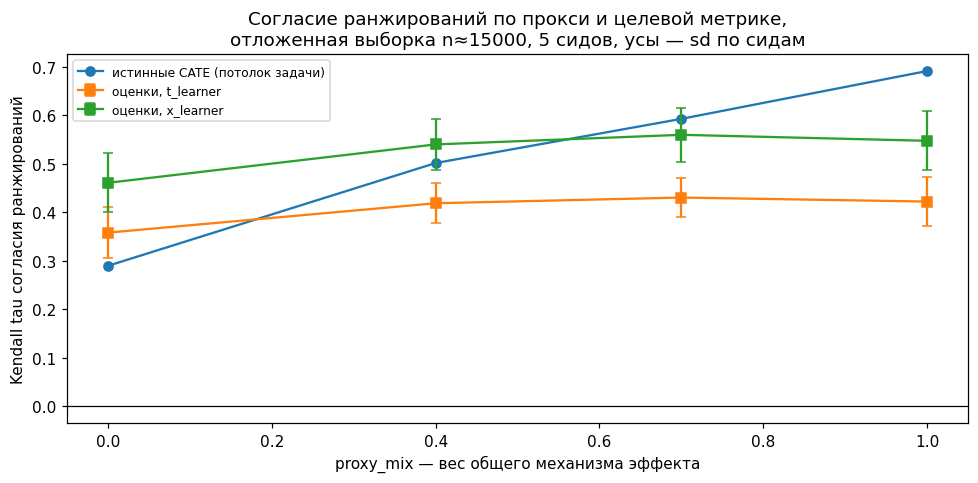

In [16]:
def plot_agreement(frame: pd.DataFrame) -> plt.Figure:
    """Согласие ранжирований против веса смеси форм эффекта."""
    fig, ax = plt.subplots()
    grouped = frame.groupby("proxy_mix")
    ax.plot(grouped["tau истинных CATE"].mean().index,
            grouped["tau истинных CATE"].mean().to_numpy(),
            marker="o", label="истинные CATE (потолок задачи)")
    for arch, sub in frame.groupby("архитектура"):
        agg = sub.groupby("proxy_mix")["tau оценок"]
        ax.errorbar(agg.mean().index, agg.mean().to_numpy(), yerr=agg.std().to_numpy(),
                    marker="s", capsize=3, label=f"оценки, {arch}")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("proxy_mix — вес общего механизма эффекта")
    ax.set_ylabel("Kendall tau согласия ранжирований")
    n_hold = int(N_CLIENTS * HOLDOUT)
    ax.set_title("Согласие ранжирований по прокси и целевой метрике,\n"
                 f"отложенная выборка n≈{n_hold}, {REPEATS} сидов, усы — sd по сидам")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


fig = plot_agreement(main)
fig.savefig(out_path("figures", f"agreement_by_mix_{RUN_TAG}", "png"))
plt.show()

## Сравнение архитектур

Прогоняется по всем сидам: на одном эксперименте разница между соседними
архитектурами меньше разброса, и рейтинг читается как случайный.

Отдельно печатается Qini на обучающей выборке — не как результат, а чтобы разрыв
с отложенной был виден: без него сравнение архитектур меряет переобучение.


In [17]:
# Таблица архитектур прогоняется по всем сидам: на одном прогоне разница между
# соседними архитектурами меньше разброса, и рейтинг читается как случайный.
t_start = time.time()
rows = []
for repeat in range(REPEATS):
    seed = SEED + 1000 * repeat
    e = make_experiment(float(SIM["effect"]["proxy_mix"]), seed)
    tr, ho = split_train_holdout(e, HOLDOUT, seed=seed + 777)
    ite = ho.ite_true["purchase"].to_numpy()
    for arch in ARCHS_ALL:
        model = build(arch, MODELS, seed=SEED, treat_prob=tr.meta["treat_prob"])
        model.fit(tr.features, tr.t, tr.y("purchase"))
        s_tr = model.predict_uplift(tr.features)
        s_ho = model.predict_uplift(ho.features)
        is_uplift = arch not in ("response_model", "random")
        rows.append({
            "архитектура": arch,
            "сид": seed,
            "qini обучение": M.qini_auc(tr.y("purchase"), tr.t, s_tr),
            "qini отложенная": M.qini_auc(ho.y("purchase"), ho.t, s_ho),
            "uplift@30%, п.п.": M.uplift_at_k(ho.y("purchase"), ho.t, s_ho, TOP_K) * 100,
            "PEHE": G.pehe(ite, s_ho) if is_uplift else np.nan,
            "tau против истины": G.rank_correlation(s_ho, ite),
            "ценность@30% от оракула": G.policy_value_ratio(ite, s_ho, TOP_K),
        })
    print("  сид %d готов, прошло %.1f мин" % (seed, (time.time() - t_start) / 60), flush=True)

archs_raw = pd.DataFrame(rows)
archs_raw.to_csv(out_path("tables", f"architectures_raw_{RUN_TAG}", "csv"), index=False)
archs = (
    archs_raw.groupby("архитектура")
    .agg(**{
        "qini обучение": ("qini обучение", "mean"),
        "qini отложенная": ("qini отложенная", "mean"),
        "qini sd": ("qini отложенная", "std"),
        "uplift@30%, п.п.": ("uplift@30%, п.п.", "mean"),
        "PEHE": ("PEHE", "mean"),
        "tau против истины": ("tau против истины", "mean"),
        "ценность@30% от оракула": ("ценность@30% от оракула", "mean"),
        "ценность sd": ("ценность@30% от оракула", "std"),
    })
    .sort_values("ценность@30% от оракула", ascending=False)
    .reset_index()
)
print(archs.round(4).to_string(index=False))
archs.to_csv(out_path("tables", f"architectures_{RUN_TAG}", "csv"), index=False)

# базовый эксперимент для последующих ячеек — первый сид
exp = make_experiment(float(SIM["effect"]["proxy_mix"]), SEED)
train, hold = split_train_holdout(exp, HOLDOUT, seed=SEED + 777)
ite_buy = hold.ite_true["purchase"].to_numpy()

  сид 42 готов, прошло 0.3 мин
  сид 1042 готов, прошло 0.7 мин
  сид 2042 готов, прошло 1.0 мин
  сид 3042 готов, прошло 1.3 мин
  сид 4042 готов, прошло 1.6 мин
         архитектура  qini обучение  qini отложенная  qini sd  uplift@30%, п.п.   PEHE  tau против истины  ценность@30% от оракула  ценность sd
           s_learner         0.0800           0.0548   0.0097           11.2450 0.1215             0.4107                   0.6935       0.0280
           x_learner         0.1481           0.0489   0.0077            9.9135 0.1242             0.3213                   0.6425       0.0377
           t_learner         0.2244           0.0437   0.0105            9.2453 0.1309             0.2809                   0.6048       0.0309
class_transformation         0.2764           0.0410   0.0087            9.1773 0.1374             0.2557                   0.5658       0.0385
              random        -0.0015          -0.0030   0.0068            2.0809    NaN            -0.0009            

## Бутстрап-интервалы: различимы ли архитектуры

Порог из плана: разница по нормированному Qini признаётся, если превышает 0.01 и
95% интервалы не перекрываются.

In [18]:
boot = []
for arch in ("s_learner", "x_learner", "t_learner", "response_model"):
    model = build(arch, MODELS, seed=SEED, treat_prob=train.meta["treat_prob"])
    model.fit(train.features, train.t, train.y("purchase"))
    s_ho = model.predict_uplift(hold.features)
    ci = M.bootstrap_ci(hold.y("purchase"), hold.t, s_ho, "qini_auc", n_boot=1000, seed=SEED)
    boot.append({"архитектура": arch, **ci})
boot = pd.DataFrame(boot)
print(boot.round(4).to_string(index=False))
print("\nпорог значимости разницы по Qini: 0.01 и неперекрывающиеся интервалы")

   архитектура  point  ci_low  ci_high     se  n_boot_used
     s_learner 0.0570  0.0432   0.0707 0.0071         1000
     x_learner 0.0520  0.0371   0.0654 0.0070         1000
     t_learner 0.0505  0.0366   0.0645 0.0071         1000
response_model 0.0004 -0.0119   0.0125 0.0063         1000

порог значимости разницы по Qini: 0.01 и неперекрывающиеся интервалы


## Кого отбирает система

Проверка содержательная, а не метрическая: система должна набирать убеждаемых и
не трогать спящих собак. `lift` — во сколько раз доля сегмента в отборе выше его
доли в populяции.

In [19]:
for arch in ("s_learner", "x_learner", "response_model"):
    model = build(arch, MODELS, seed=SEED, treat_prob=train.meta["treat_prob"])
    model.fit(train.features, train.t, train.y("purchase"))
    rec = G.segment_recovery(hold.segment, model.predict_uplift(hold.features), TOP_K)
    print(f"--- {arch}, топ-{int(TOP_K * 100)}% ---")
    print(rec.round(3).to_string(index=False), "\n")
    rec.to_csv(out_path("tables", f"segments_{arch}_{RUN_TAG}", "csv"), index=False)

--- s_learner, топ-30% ---
     segment  n_in_top  share_in_top  share_in_population  lift
  lost_cause      1568         0.346                0.456 0.759
  sure_thing      1103         0.243                0.247 0.985
 persuadable      1779         0.392                0.200 1.964
sleeping_dog        85         0.019                0.098 0.192 

--- x_learner, топ-30% ---
     segment  n_in_top  share_in_top  share_in_population  lift
  lost_cause      1536         0.339                0.456 0.743
  sure_thing      1065         0.235                0.247 0.951
 persuadable      1838         0.405                0.200 2.029
sleeping_dog        96         0.021                0.098 0.217 

--- response_model, топ-30% ---
     segment  n_in_top  share_in_top  share_in_population  lift
  lost_cause      1830         0.404                0.456 0.886
  sure_thing      1301         0.287                0.247 1.162
 persuadable      1094         0.241                0.200 1.208
sleeping_dog  

## Ось дизайна: доля контроля

Второй результат статьи: как качество отбора зависит от того, сколько клиентов
отдано в контроль. Меньше контроля — больше охват, но хуже обучение.

In [20]:
t_start = time.time()
rows = []
for control_share in EXP["grid"]["control_share"]:
    for repeat in range(REPEATS):
        seed = SEED + 1000 * repeat
        e = make_experiment(float(SIM["effect"]["proxy_mix"]), seed, control_share=control_share)
        tr, ho = split_train_holdout(e, HOLDOUT, seed=seed + 777)
        ite = ho.ite_true["purchase"].to_numpy()
        for arch in ARCHS_CONTROL:
            s = fit_score(tr, ho, arch, "purchase")
            rows.append({
                "доля контроля": control_share,
                "архитектура": arch,
                "сид": seed,
                "qini отложенная": M.qini_auc(ho.y("purchase"), ho.t, s),
                "tau против истины": G.rank_correlation(s, ite),
                "ценность@30%": G.policy_value_ratio(ite, s, TOP_K),
            })
    print("  доля контроля %.1f готова, прошло %.1f мин"
          % (control_share, (time.time() - t_start) / 60), flush=True)
control = pd.DataFrame(rows)
control_summary = (control.groupby(["доля контроля", "архитектура"])
                   [["qini отложенная", "tau против истины", "ценность@30%"]]
                   .agg(["mean", "std"]))
print(control_summary.round(4).to_string())
control.to_csv(out_path("tables", f"control_share_axis_{RUN_TAG}", "csv"), index=False)

  доля контроля 0.5 готова, прошло 1.3 мин
  доля контроля 0.3 готова, прошло 3.3 мин
  доля контроля 0.1 готова, прошло 4.1 мин
                             qini отложенная         tau против истины         ценность@30%        
                                        mean     std              mean     std         mean     std
доля контроля архитектура                                                                          
0.1           response_model         -0.0003  0.0094            0.0518  0.0964       0.1667  0.0468
              s_learner               0.0487  0.0120            0.3917  0.0412       0.6626  0.0276
              t_learner               0.0381  0.0107            0.2333  0.0306       0.5503  0.0256
              x_learner               0.0396  0.0125            0.2538  0.0389       0.5561  0.0238
0.3           response_model          0.0045  0.0086            0.0505  0.0969       0.1648  0.0448
              s_learner               0.0548  0.0097            0.4107 

### Рисунок к оси доли контроля

Отдельная ячейка: рисунок в прогоне не сохранялся, а в статью он нужен.
Читает таблицу оси из памяти, а если ядро перезапущено — с диска.


In [ ]:
if "control" not in dir():
    control = pd.read_csv(out_path("tables", f"control_share_axis_{RUN_TAG}", "csv"))


def plot_control_share(frame: pd.DataFrame) -> plt.Figure:
    """Ценность отобранного сегмента против доли контроля, усы — sd по сидам."""
    fig, ax = plt.subplots()
    for arch in ARCHS_CONTROL:
        agg = frame[frame["архитектура"] == arch].groupby("доля контроля")["ценность@30%"]
        ax.errorbar(agg.mean().index, agg.mean().to_numpy(), yerr=agg.std().to_numpy(),
                    marker="o", capsize=3, label=arch)
    ax.set_xlabel("доля клиентов в контрольной группе")
    ax.set_ylabel("ценность топ-30% от оракула")
    ax.set_title("Половина в контроле не даёт выигрыша против трети;\n"
                 f"10% дороже всего для X- и T-learner. {REPEATS} сидов, усы — sd по сидам")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


fig = plot_control_share(control)
fig.savefig(out_path("figures", f"value_by_control_share_{RUN_TAG}", "png"))
plt.show()

# сводка той же оси — в статью идёт она, а не сырая ось
control_summary = (control.groupby(["доля контроля", "архитектура"])
                   [["qini отложенная", "tau против истины", "ценность@30%"]]
                   .agg(["mean", "std"]).round(4))
control_summary.to_csv(out_path("tables", f"control_share_{RUN_TAG}", "csv"))
print(control_summary.to_string())


## Кривые Qini

Сохраняются как рабочий график: по нему видно, на какой доле аудитории
прекращается прирост.

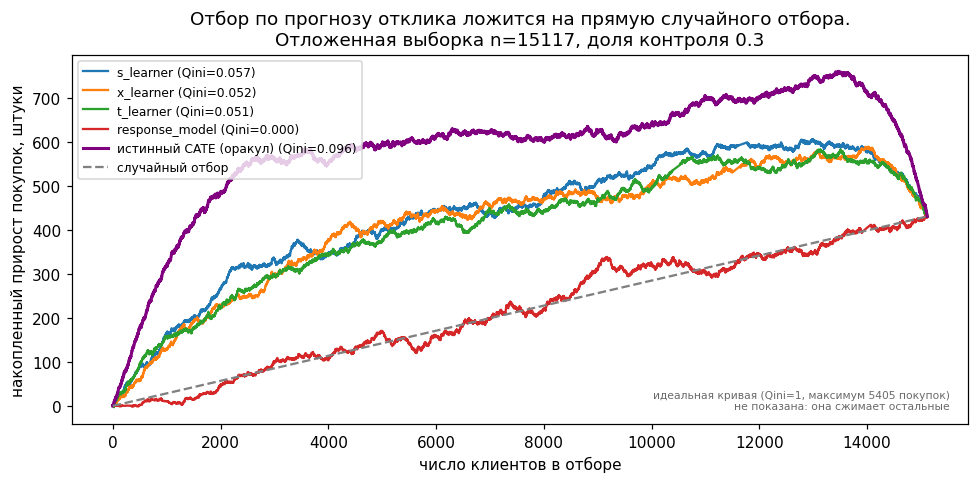

In [21]:
def plot_qini(holdout, scores: dict[str, np.ndarray]) -> plt.Figure:
    """Кривые Qini на отложенной выборке. Ось Y — накопленные отклики, штуки.

    Идеальная кривая не рисуется: она выше рабочих в семь раз и сжимает их в
    нечитаемую полосу у оси. Её максимум вынесен в подпись, а нормировка на неё
    и так сидит в коэффициенте Qini в легенде.
    """
    fig, ax = plt.subplots()
    y, t = holdout.y("purchase"), holdout.t
    for label, score in scores.items():
        style = {"lw": 2, "color": "purple"} if "оракул" in label else {}
        x, curve = M.qini_curve(y, t, score)
        ax.plot(x, curve, label=f"{label} (Qini={M.qini_auc(y, t, score):.3f})", **style)
    x_p, y_p = M.perfect_qini_curve(y, t)
    ax.plot([0, x_p[-1]], [0, y_p[-1]], ls="--", color="gray", label="случайный отбор")
    ax.set_xlabel("число клиентов в отборе")
    ax.set_ylabel("накопленный прирост покупок, штуки")
    ax.set_title("Отбор по прогнозу отклика ложится на прямую случайного отбора.\n"
                 f"Отложенная выборка n={holdout.n}, доля контроля {CONTROL_SHARE}")
    ax.annotate(f"идеальная кривая (Qini=1, максимум {int(y_p.max())} покупок)\n"
                "не показана: она сжимает остальные",
                xy=(0.98, 0.04), xycoords="axes fraction", ha="right",
                fontsize=7, color="dimgray")
    ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    return fig


scores = {}
for arch in ("s_learner", "x_learner", "t_learner", "response_model"):
    model = build(arch, MODELS, seed=SEED, treat_prob=train.meta["treat_prob"])
    model.fit(train.features, train.t, train.y("purchase"))
    scores[arch] = model.predict_uplift(hold.features)
scores["истинный CATE (оракул)"] = ite_buy

fig = plot_qini(hold, scores)
fig.savefig(out_path("figures", f"qini_curves_{RUN_TAG}", "png"))
plt.show()

## Что идёт в статью

Ниже — сводка, которую можно переносить в текст. Числа берутся из таблиц выше,
руками ничего не переписывается.

In [22]:
best_mix = summary[summary["proxy_mix"] == max(MIX_VALUES)].iloc[0]
work_mix = summary[summary["proxy_mix"] == float(SIM["effect"]["proxy_mix"])].iloc[0]
print("ПОТОЛОК ЗАДАЧИ. При общем механизме эффекта (proxy_mix=%.1f, корреляция форм %.2f)"
      % (best_mix["proxy_mix"], best_mix["corr форм"]))
print("  согласие истинных CATE: tau = %.3f" % best_mix["tau истины"])
print("  согласие оценок моделей: tau = %.3f" % best_mix["tau оценок"])
print("  то есть обучение забирает ещё %.3f согласия" % (best_mix["tau истины"] - best_mix["tau оценок"]))
print("\nРАБОЧАЯ КОНФИГУРАЦИЯ (proxy_mix=%.1f):" % work_mix["proxy_mix"])
print("  tau истинных CATE %.3f, tau оценок %.3f" % (work_mix["tau истины"], work_mix["tau оценок"]))
print("  ценность топ-30%%: по целевой метрике %.3f, по прокси %.3f, потеря %.3f от оракула"
      % (work_mix["ценность целевой"], work_mix["ценность прокси"], work_mix["потеря ценности"]))
print("\nСРАВНЕНИЕ С ТЕКУЩЕЙ ПРАКТИКОЙ (отбор по прогнозной модели отклика):")
r = archs.set_index("архитектура")
for arch in ("s_learner", "x_learner", "t_learner", "response_model", "random"):
    if arch in r.index:
        print("  %-20s qini %+.4f ± %.4f, ценность@30%% %.3f ± %.3f"
              % (arch, r.loc[arch, "qini отложенная"], r.loc[arch, "qini sd"],
                 r.loc[arch, "ценность@30% от оракула"], r.loc[arch, "ценность sd"]))
print("\nЦЕНА КОНТРОЛЯ (ось доли контроля, ценность@30%):")
pivot = (control.groupby(["доля контроля", "архитектура"])["ценность@30%"]
         .mean().unstack().round(3))
print(pivot.to_string())
print("\nверсии: pandas %s, numpy %s | seed %d | прогон %s"
      % (pd.__version__, np.__version__, SEED, RUN_DATE))

ПОТОЛОК ЗАДАЧИ. При общем механизме эффекта (proxy_mix=1.0, корреляция форм 1.00)
  согласие истинных CATE: tau = 0.691
  согласие оценок моделей: tau = 0.422
  то есть обучение забирает ещё 0.269 согласия

РАБОЧАЯ КОНФИГУРАЦИЯ (proxy_mix=0.7):
  tau истинных CATE 0.592, tau оценок 0.430
  ценность топ-30%: по целевой метрике 0.605, по прокси 0.609, потеря -0.004 от оракула

СРАВНЕНИЕ С ТЕКУЩЕЙ ПРАКТИКОЙ (отбор по прогнозной модели отклика):
  s_learner            qini +0.0548 ± 0.0097, ценность@30% 0.694 ± 0.028
  x_learner            qini +0.0489 ± 0.0077, ценность@30% 0.643 ± 0.038
  t_learner            qini +0.0437 ± 0.0105, ценность@30% 0.605 ± 0.031
  response_model       qini +0.0045 ± 0.0086, ценность@30% 0.165 ± 0.045
  random               qini -0.0030 ± 0.0068, ценность@30% 0.186 ± 0.019

ЦЕНА КОНТРОЛЯ (ось доли контроля, ценность@30%):
архитектура    response_model  s_learner  t_learner  x_learner
доля контроля                                                 
0.1          